# B1. Lingkungan Kerja dan Formulasi Masalah (SIMUTEH)
SEED = 1014. Notebook dijalankan dari folder `notebook/`.

OpenCV 5.0.0 | NumPy 2.4.6 | scikit-image 0.26.0
shape: (480, 640, 3) dtype: uint8
min-maks: 0 255
piksel (y=100, x=200) dalam urutan BGR: [196 175 206]


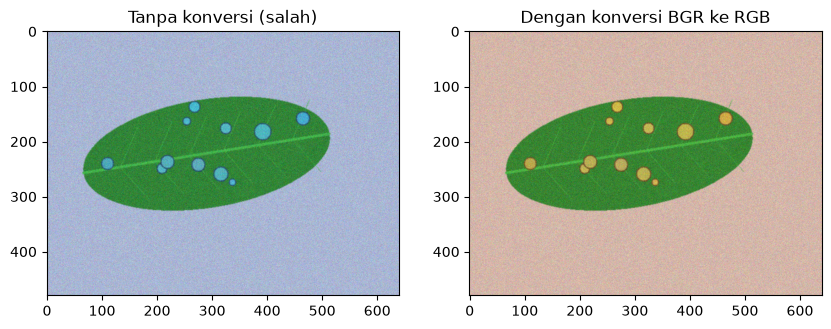

In [1]:
import sys
sys.path.append("../src")  # agar utils_cv dapat diimpor dari notebook/
import cv2, numpy as np, skimage, matplotlib.pyplot as plt
from utils_cv import baca, tampil
print("OpenCV", cv2.__version__, "| NumPy", np.__version__,
      "| scikit-image", skimage.__version__)
img = baca("../data/sintetis/citra/teh_041.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])
# tampilkan citra TANPA dan DENGAN konversi BGR ke RGB
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB"); plt.savefig("../hasil/b1_bgr_rgb.png")

## Piksel di dalam daun (untuk P1.1)
Piksel (y=100, x=200) berada di latar nampan. Berikut satu piksel pada daun dan satu pada bercak.

In [2]:
md = cv2.imread("../data/sintetis/mask_daun/teh_041.png", 0)
mb = cv2.imread("../data/sintetis/mask_bercak/teh_041.png", 0)
ys, xs = np.where((md > 0) & (mb == 0)); i = len(ys)//2
print("piksel daun sehat  (y=%d,x=%d) BGR:" % (ys[i], xs[i]), img[ys[i], xs[i]])
ys, xs = np.where(mb > 0); i = len(ys)//2
print("piksel bercak      (y=%d,x=%d) BGR:" % (ys[i], xs[i]), img[ys[i], xs[i]])
print("jumlah angka satu citra:", img.size)

piksel daun sehat  (y=222,x=181) BGR: [ 51 131  51]
piksel bercak      (y=230,x=211) BGR: [ 75 134 160]
jumlah angka satu citra: 921600


## Diagram pipeline SIMUTEH (enam tahap)

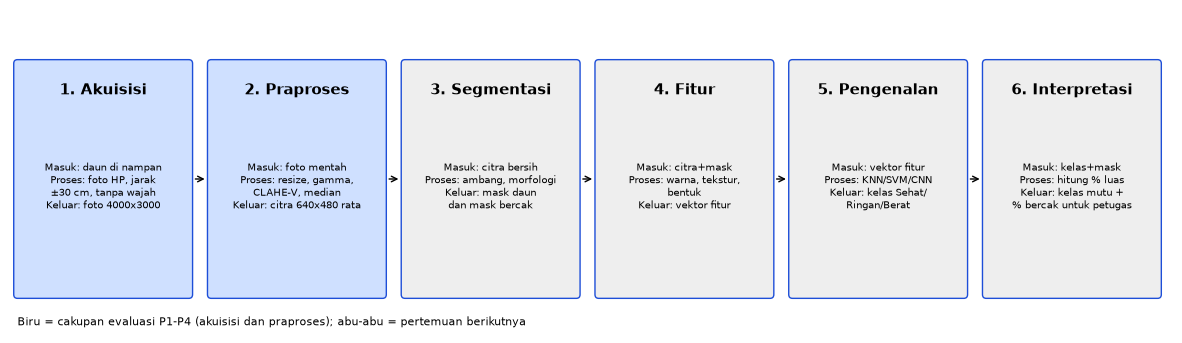

In [3]:
import matplotlib.patches as mp
tahap = [
 ("1. Akuisisi", "Masuk: daun di nampan\nProses: foto HP, jarak\n±30 cm, tanpa wajah\nKeluar: foto 4000x3000"),
 ("2. Praproses", "Masuk: foto mentah\nProses: resize, gamma,\nCLAHE-V, median\nKeluar: citra 640x480 rata"),
 ("3. Segmentasi", "Masuk: citra bersih\nProses: ambang, morfologi\nKeluar: mask daun\ndan mask bercak"),
 ("4. Fitur", "Masuk: citra+mask\nProses: warna, tekstur,\nbentuk\nKeluar: vektor fitur"),
 ("5. Pengenalan", "Masuk: vektor fitur\nProses: KNN/SVM/CNN\nKeluar: kelas Sehat/\nRingan/Berat"),
 ("6. Interpretasi", "Masuk: kelas+mask\nProses: hitung % luas\nKeluar: kelas mutu +\n% bercak untuk petugas"),
]
fig, ax = plt.subplots(figsize=(15, 4.2)); ax.set_xlim(0, 15.6); ax.set_ylim(0, 4.2); ax.axis("off")
for i, (j, t) in enumerate(tahap):
    x = 0.1 + i * 2.6
    warna = "#cfe0ff" if i < 2 else "#eeeeee"
    ax.add_patch(mp.FancyBboxPatch((x, 0.5), 2.3, 3.0, boxstyle="round,pad=0.05", fc=warna, ec="#1d4ed8"))
    ax.text(x + 1.15, 3.1, j, ha="center", weight="bold", fontsize=11)
    ax.text(x + 1.15, 1.9, t, ha="center", va="center", fontsize=7.5)
    if i < 5: ax.annotate("", xy=(x + 2.55, 2.0), xytext=(x + 2.35, 2.0), arrowprops=dict(arrowstyle="->"))
ax.text(0.1, 0.1, "Biru = cakupan evaluasi P1-P4 (akuisisi dan praproses); abu-abu = pertemuan berikutnya", fontsize=8)
plt.savefig("../hasil/b1_pipeline.png", dpi=130, bbox_inches="tight")